In [1]:
import torch
from torchvision.transforms import ToTensor
from torchvision.datasets import CIFAR10
import matplotlib.pyplot as plt

In [2]:
dataset = CIFAR10(
    root="./Data",
    train=True,
    download=True,
    transform=ToTensor()
)

x = []
for img, label in dataset:
    if label == 1:
        x.append(img.flatten())

x = torch.stack(x)
print(x.shape)

torch.Size([5000, 3072])


In [3]:
def visualize(img):
    plt.imshow(img.reshape(3,32,32).cpu().permute(1, 2, 0).numpy())
    plt.axis("off")
    plt.show()

In [4]:
mean = sum(x) / len(x)

S = torch.zeros((3*32*32, 3*32*32))

for i in x:
    d = (i - mean).reshape(3*32*32,1)
    S += d @ d.T

S /= len(x)

eigenvalues, eigenvectors = torch.linalg.eigh(S)

In [5]:
m = 150

W = eigenvectors[:,-m:]
X = (x - mean) @ W
print(f'{x.shape} * {W.shape} = {X.shape}')

torch.Size([5000, 3072]) * torch.Size([3072, 150]) = torch.Size([5000, 150])


In [6]:
reconstruction = X @ W.T + mean
print(f'{X.shape} * {W.T.shape} = {reconstruction.shape}')

torch.Size([5000, 150]) * torch.Size([150, 3072]) = torch.Size([5000, 3072])


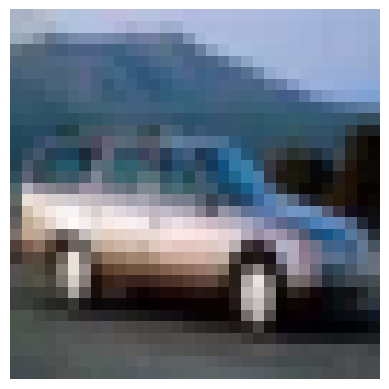

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.10160065..1.0310175].


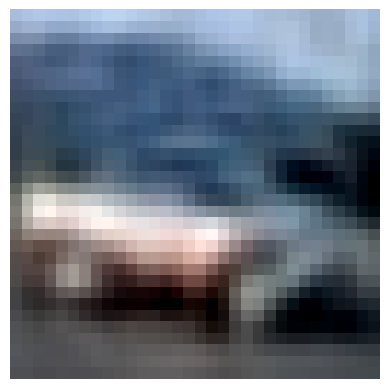

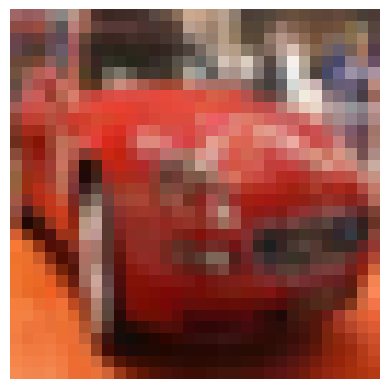

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.15497059..0.9717032].


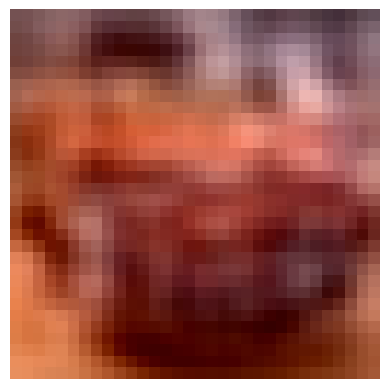

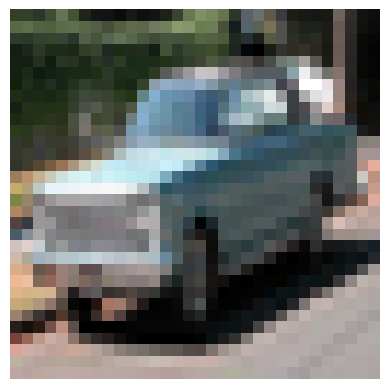

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.10800004..1.0311753].


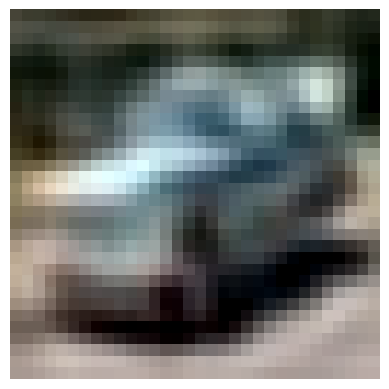

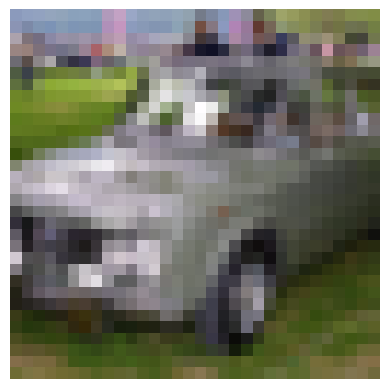

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.003019601..0.8636658].


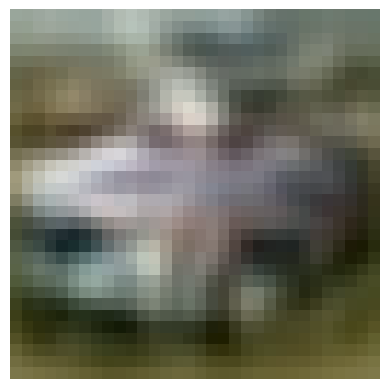

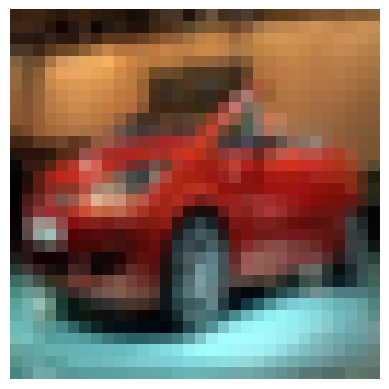

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.111132234..1.0028352].


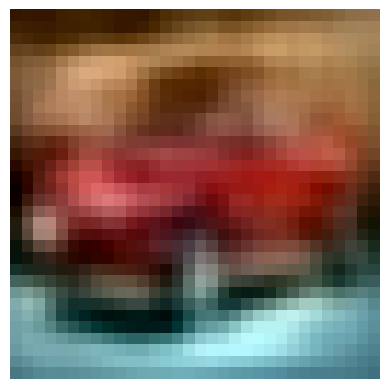

In [7]:
for i in range(5):
    visualize(x[i])
    visualize(reconstruction[i])